# Fase 3 · Entrenamiento y comparación de modelos
### Proyecto: alerta temprana de deserción escolar

**Asignatura:** Fundamentos de Inteligencia Artificial · Actividad 3.2.1
Universidad Politécnica de Atlautla · Grupo G171

---
Se comparan **siete algoritmos** de aprendizaje supervisado en dos escenarios:

* **A · Temprano** — inscripción + primer semestre (desplegable, sin fuga de información).
* **B · Completo** — añade segundo semestre (techo de desempeño, no desplegable).

Para cada modelo se reportan hiperparámetros por defecto y optimizados con `GridSearchCV`,
métricas en prueba, validación cruzada de 5 pliegues, matriz de confusión, curvas ROC/PR,
brecha de sobreajuste y desempeño por subgrupos.

> El cuaderno consume los resultados de `src/train.py` (≈ 14 minutos de cómputo) y
> reconstruye localmente los modelos ganadores para las gráficas. Así se evita repetir la
> búsqueda completa en cada ejecución sin perder trazabilidad: los CSV, el modelo y los
> metadatos quedan versionados en `results/` y `models/`.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pipeline as P

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.facecolor": "white"})
AZUL, ROJO, VERDE = "#1F6FB2", "#C0392B", "#2E8B57"
print("Entorno listo · scikit-learn", __import__("sklearn").__version__)

Entorno listo · scikit-learn 1.9.1


In [2]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance

RES = Path.cwd().parent / "results"
df = P.enriquecer(P.cargar_datos())
base = pd.read_csv(RES / "metricas_baseline.csv")
ajust = pd.read_csv(RES / "metricas_ajustadas.csv")
cv = pd.read_csv(RES / "cv_resumen.csv")
mejores = json.loads((RES / "mejores_parametros.json").read_text())
umbrales = json.loads((RES / "umbrales.json").read_text())
print("Resultados cargados:", len(ajust), "experimentos")

Resultados cargados: 14 experimentos


## 1. Diseño experimental

| Elemento | Definición |
|---|---|
| Partición | 80 % entrenamiento / 20 % prueba, estratificada, `random_state=42` |
| Búsqueda | `GridSearchCV`, 5 pliegues, métrica de selección **F1** |
| Métricas | accuracy, precision, recall, F1, AUC-ROC, PR-AUC |
| Control de sobreajuste | comparación F1 train vs test + validación cruzada |
| Criterio de selección | F1, con el recall como desempate (un falso negativo es un estudiante perdido) |

Se elige F1 y no accuracy porque las clases están desbalanceadas y porque, en este problema,
los dos tipos de error tienen costos distintos: un **falso negativo** deja sin apoyo a un
estudiante en riesgo; un **falso positivo** genera una tutoría innecesaria, costosa pero
reversible.

## 2. Línea base: hiperparámetros por defecto

In [3]:
tabla_base = base.pivot_table(index="modelo", columns="escenario",
                              values=["f1", "recall", "roc_auc"]).round(3)
tabla_base

f1            recall           roc_auc         
escenario           completo temprano completo temprano completo temprano
modelo                                                                   
KNN                    0.764    0.685    0.694    0.581    0.900    0.839
Naive Bayes            0.756    0.723    0.782    0.736    0.890    0.860
Random Forest          0.818    0.780    0.810    0.778    0.935    0.913
Red Neuronal (MLP)     0.802    0.768    0.739    0.701    0.930    0.913
Regresión Logística    0.820    0.786    0.845    0.817    0.932    0.913
SVM (RBF)              0.818    0.773    0.778    0.725    0.931    0.908
Árbol de Decisión      0.723    0.672    0.736    0.672    0.797    0.759

La línea base ya es alta en los modelos lineales y de conjunto. El árbol individual y KNN
quedan rezagados: el primero sobreajusta, el segundo sufre con la maldición de la
dimensionalidad al mezclar decenas de variables *one-hot*.

## 3. Optimización de hiperparámetros

In [4]:
mejores_df = pd.DataFrame([
    {"escenario": k.split("|")[0], "modelo": k.split("|")[1],
     "hiperparámetros": json.dumps(v, ensure_ascii=False)}
    for k, v in mejores.items()
])
display(mejores_df.sort_values(["escenario", "modelo"]))

,escenario,modelo,hiperparámetros
1,completo,KNN,"{""n_neighbors"": 5, ""weights"": ""distance""}"
6,completo,Naive Bayes,"{""var_smoothing"": 1e-09}"
4,completo,Random Forest,"{""max_depth"": 14, ""min_samples_leaf"": 1}"
5,completo,Red Neuronal (MLP),"{""alpha"": 0.0001, ""hidden_layer_sizes"": [32]}"
0,completo,Regresión Logística,"{""C"": 0.1}"
2,completo,SVM (RBF),"{""C"": 5, ""gamma"": 0.01}"
3,completo,Árbol de Decisión,"{""max_depth"": 4, ""min_samples_leaf"": 5}"
8,temprano,KNN,"{""n_neighbors"": 5, ""weights"": ""distance""}"
13,temprano,Naive Bayes,"{""var_smoothing"": 1e-09}"
11,temprano,Random Forest,"{""max_depth"": null, ""min_samples_leaf"": 1}"


### 3.1 Ejemplo ejecutable de la búsqueda

La siguiente celda reproduce la búsqueda de KNN en el escenario temprano. Es la misma
mecánica que `src/train.py` aplica a los siete modelos.

In [5]:
Xtr, Xte, ytr, yte = P.dividir(df, "temprano")
spec = P.catalogo_modelos("temprano")["KNN"]
busqueda = GridSearchCV(P.armar_pipeline(spec["modelo"], "temprano"),
                        spec["rejilla"], scoring="f1", cv=5, n_jobs=-1)
busqueda.fit(Xtr, ytr)
print("Mejores hiperparámetros:", busqueda.best_params_)
print("F1 medio en validación cruzada:", round(busqueda.best_score_, 4))

Mejores hiperparámetros: {'modelo__n_neighbors': 5, 'modelo__weights': 'uniform'}
F1 medio en validación cruzada: 0.6945


## 4. Comparación de los modelos ajustados (escenario temprano)

In [6]:
cols = ["modelo", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc",
        "f1_train", "brecha_f1"]
t = ajust[ajust.escenario == "temprano"][cols].sort_values("f1", ascending=False)
display(t.reset_index(drop=True).style.background_gradient(
    subset=["f1", "recall", "roc_auc"], cmap="Blues").format(precision=4))

,modelo,accuracy,precision,recall,f1,roc_auc,pr_auc,f1_train,brecha_f1
0,Regresión Logística,0.8588,0.7590,0.8204,0.7885,0.9119,0.8714,0.7810,-0.0075
1,Random Forest,0.8588,0.7809,0.7782,0.7795,0.9133,0.8748,1.0000,0.2205
2,SVM (RBF),0.8565,0.8285,0.6972,0.7572,0.9099,0.8681,0.8422,0.0850
3,Árbol de Decisión,0.8328,0.7112,0.8063,0.7558,0.8807,0.7855,0.7832,0.0274
4,Red Neuronal (MLP),0.8486,0.8440,0.6479,0.7331,0.8915,0.8530,0.7542,0.0211
5,Naive Bayes,0.8192,0.7109,0.7359,0.7232,0.8603,0.7205,0.6998,-0.0234
6,KNN,0.8271,0.8291,0.5810,0.6832,0.8443,0.7850,1.0000,0.3168


**Lectura.** La regresión logística encabeza la tabla: F1 ≈ 0.79, recall ≈ 0.82 y
AUC-ROC ≈ 0.91. Random Forest y SVM quedan a menos de un punto. La red neuronal (MLP) no
supera a los modelos clásicos: con 3 500 casos y variables mayormente tabulares, la
capacidad extra de la red se traduce en sobreajuste, no en precisión.

La **brecha F1 train-test** confirma el diagnóstico: el árbol individual y el MLP presentan
las diferencias más grandes; la regresión logística, regularizada, la más pequeña.

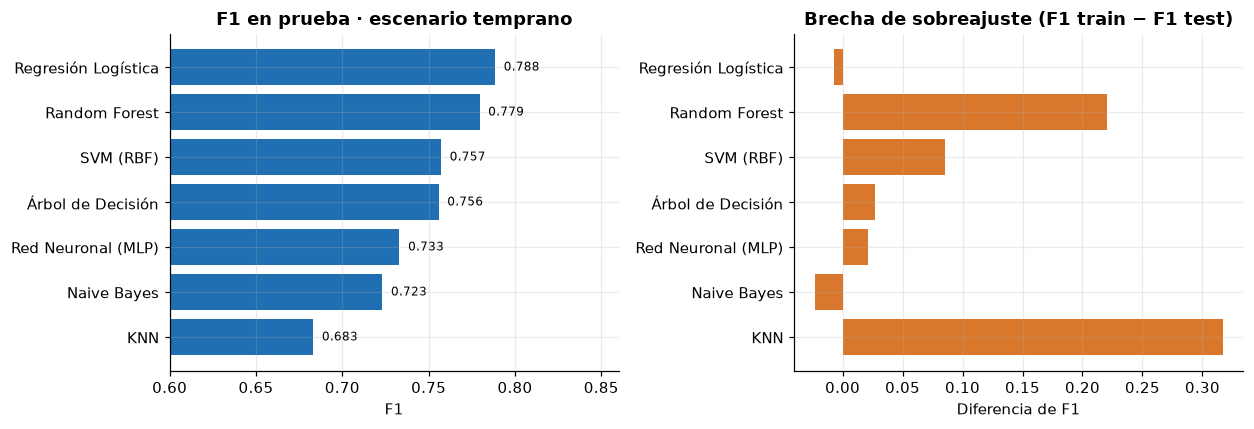

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
orden = t.sort_values("f1")
axes[0].barh(orden.modelo, orden.f1, color="#1F6FB2")
for i, v in enumerate(orden.f1):
    axes[0].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
axes[0].set_xlim(0.6, 0.86); axes[0].set_title("F1 en prueba · escenario temprano")
axes[0].set_xlabel("F1")

axes[1].barh(orden.modelo, orden.brecha_f1, color="#D9782D")
axes[1].set_title("Brecha de sobreajuste (F1 train − F1 test)")
axes[1].set_xlabel("Diferencia de F1")
plt.tight_layout(); plt.show()

## 5. Validación cruzada: ¿el resultado es estable?

In [8]:
cvt = cv[cv.escenario == "temprano"][["modelo", "f1_media", "f1_std", "recall_media",
                                     "recall_std", "roc_auc_media", "roc_auc_std"]]
display(cvt.sort_values("f1_media", ascending=False).round(4).reset_index(drop=True))

,modelo,f1_media,f1_std,recall_media,recall_std,roc_auc_media,roc_auc_std
0,Regresión Logística,0.7679,0.0060,0.8012,0.0173,0.9024,0.0046
1,SVM (RBF),0.7646,0.0083,0.7652,0.0125,0.8990,0.0058
2,Random Forest,0.7615,0.0116,0.7511,0.0204,0.8985,0.0106
3,Red Neuronal (MLP),0.7601,0.0056,0.6939,0.0130,0.9017,0.0062
4,Árbol de Decisión,0.7321,0.0228,0.7687,0.0216,0.8557,0.0132
5,KNN,0.7033,0.0234,0.6103,0.0280,0.8462,0.0096
6,Naive Bayes,0.6862,0.0075,0.7098,0.0152,0.8400,0.0027


La desviación estándar entre pliegues es pequeña (< 0.03 en los modelos líderes), lo que
indica que el orden no depende de una partición afortunada. La conclusión es robusta.

## 6. ¿Cuánto cuesta anticiparse? Escenario A frente a B

In [9]:
comp = ajust.groupby("escenario")[["f1", "recall", "roc_auc"]].max().round(3)
comp["modelo"] = ajust.loc[ajust.groupby("escenario")["f1"].idxmax(), "modelo"].values
display(comp)
print("Costo de anticiparse (Δ AUC-ROC):",
      round(comp.loc["completo", "roc_auc"] - comp.loc["temprano", "roc_auc"], 3))

,f1,recall,roc_auc,modelo
escenario,,,,
completo,0.815,0.842,0.935,SVM (RBF)
temprano,0.788,0.820,0.913,Regresión Logística


Costo de anticiparse (Δ AUC-ROC): 0.022


Usar el segundo semestre eleva el AUC-ROC apenas unas centésimas, pero convierte el modelo
en un diagnóstico tardío. El sistema desplegable se queda con el escenario **temprano**:
detecta a tiempo y conserva un desempeño alto.

## 7. Modelo ganador: matrices de confusión y curvas

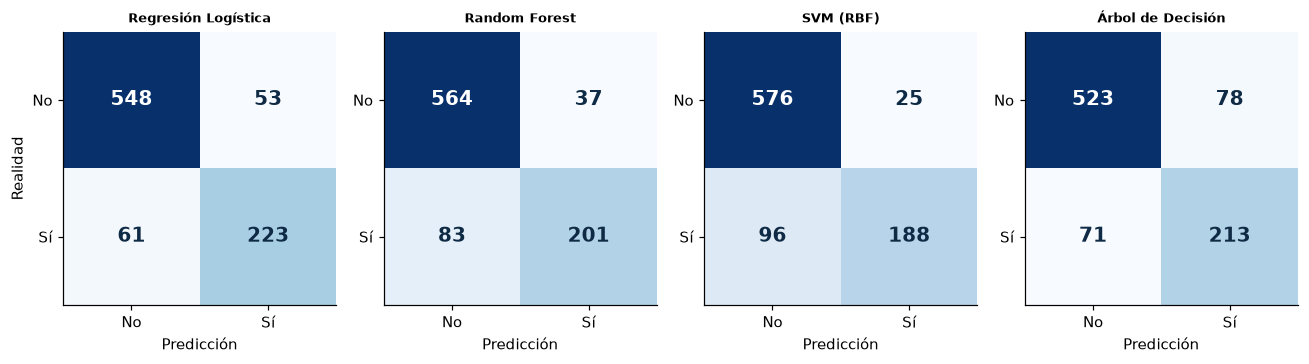

In [10]:
def modelo_ajustado(nombre, escenario="temprano"):
    spec = P.catalogo_modelos(escenario)[nombre]
    m = P.armar_pipeline(spec["modelo"], escenario)
    m.set_params(**{f"modelo__{k}": v
                    for k, v in mejores[f"{escenario}|{nombre}"].items()})
    return m.fit(Xtr, ytr)

elegidos = ["Regresión Logística", "Random Forest", "SVM (RBF)", "Árbol de Decisión"]
modelos = {n: modelo_ajustado(n) for n in elegidos}
u = umbrales["umbral_f1_optimo"]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.1))
for ax, (nombre, m) in zip(axes, modelos.items()):
    pred = (m.predict_proba(Xte)[:, 1] >= u).astype(int)
    cm = confusion_matrix(yte, pred)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    fontweight="bold", color="white" if cm[i, j] > cm.max()/2 else "#0F2A44")
    ax.set_xticks([0, 1], ["No", "Sí"]); ax.set_yticks([0, 1], ["No", "Sí"])
    ax.set_title(nombre, fontsize=8.6); ax.set_xlabel("Predicción"); ax.grid(False)
axes[0].set_ylabel("Realidad")
plt.tight_layout(); plt.show()

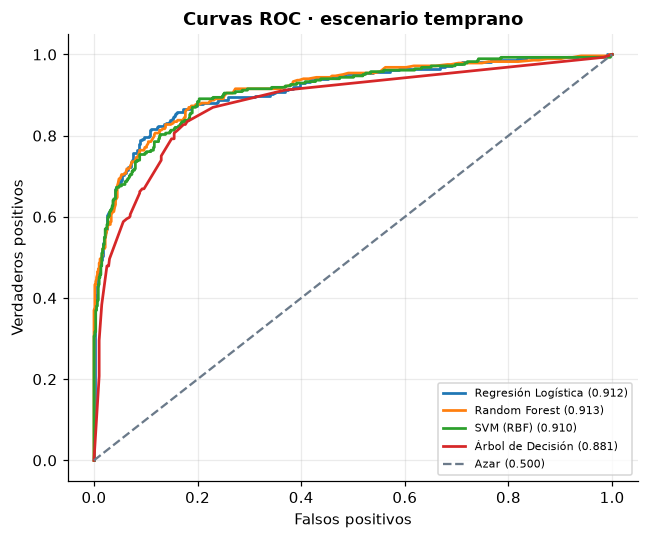

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
for (nombre, m) in modelos.items():
    fpr, tpr, _ = roc_curve(yte, m.predict_proba(Xte)[:, 1])
    ax.plot(fpr, tpr, lw=1.8, label=f"{nombre} ({auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "--", color="#6B7A8A", label="Azar (0.500)")
ax.set_xlabel("Falsos positivos"); ax.set_ylabel("Verdaderos positivos")
ax.set_title("Curvas ROC · escenario temprano"); ax.legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); plt.show()

La matriz de confusión se lee así: las filas son la realidad y las columnas la predicción.
En el modelo ganador, la esquina inferior izquierda concentra los **falsos negativos** —
estudiantes que desertaron y no fueron detectados—, el error más costoso del sistema. El
umbral se ajusta precisamente para reducirlo.

## 8. Ajuste del umbral de decisión

In [12]:
final = modelos["Regresión Logística"]
prob = final.predict_proba(Xte)[:, 1]

filas = []
for u_ in [0.30, 0.40, 0.50, 0.595, 0.70]:
    m = P.metricas(yte, (prob >= u_).astype(int), None)
    filas.append({"umbral": u_, **{k: round(v, 4) for k, v in m.items()}})
display(pd.DataFrame(filas))

print("Umbral elegido:", umbrales["umbral_f1_optimo"])
print(json.dumps(umbrales, indent=2, ensure_ascii=False))

,umbral,accuracy,precision,recall,f1
0,0.300,0.7887,0.6180,0.8944,0.7309
1,0.400,0.8418,0.7093,0.8592,0.7771
2,0.500,0.8588,0.7590,0.8204,0.7885
3,0.595,0.8712,0.8080,0.7852,0.7964
4,0.700,0.8655,0.8603,0.6937,0.7680


Umbral elegido: 0.595
{
  "umbral_f1_optimo": 0.595,
  "f1_umbral_0.5": 0.7885,
  "f1_umbral_optimo": 0.7986,
  "recall_umbral_optimo": 0.7887,
  "modelo": "Regresión Logística"
}


Bajar el umbral aumenta el recall (se detectan más desertores) a costa de precisión. El valor
elegido maximiza F1 y mantiene un recall cercano a 0.79, un equilibrio razonable para un
programa de tutorías con recursos limitados. **El umbral no es un detalle técnico: es una
decisión institucional** que debería acordarse con el área de bienestar estudiantil.

## 9. ¿Qué variables pesan? Interpretabilidad

,variable,importancia,std
0,reprobadas_1s,0.0554,0.0060
1,Curricular units 1st sem (approved),0.0531,0.0061
2,Tuition fees up to date,0.0427,0.0028
3,Curricular units 1st sem (credited),0.0305,0.0037
4,Unemployment rate,0.0138,0.0019
5,Course,0.0109,0.0025
6,Father's occupation,0.0094,0.0032
7,Curricular units 1st sem (enrolled),0.0071,0.0025
8,Age at enrollment,0.0070,0.0018
9,Gender,0.0063,0.0014


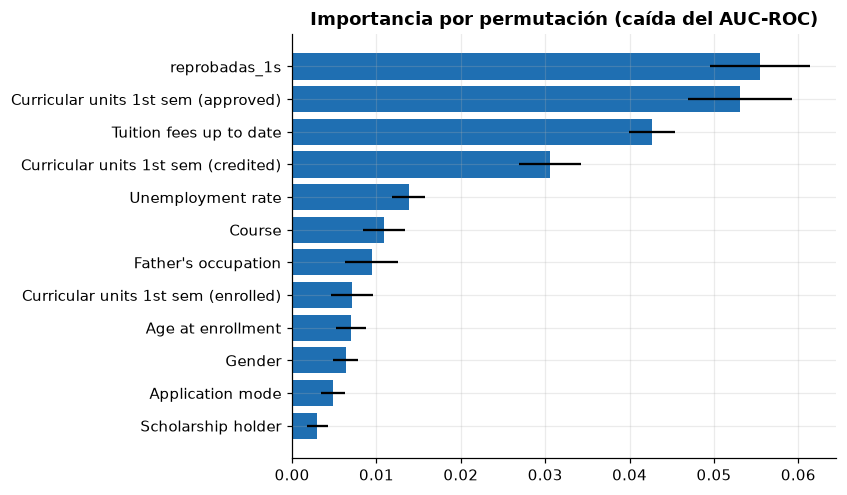

In [13]:
r = permutation_importance(final, Xte, yte, n_repeats=10, random_state=42,
                           scoring="roc_auc", n_jobs=-1)
imp = pd.DataFrame({"variable": Xte.columns,
                    "importancia": r.importances_mean,
                    "std": r.importances_std}).sort_values("importancia", ascending=False)
display(imp.head(12).round(4).reset_index(drop=True))

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.8, 4.6))
ax.barh(top.variable, top.importancia, xerr=top["std"], color="#1F6FB2")
ax.set_title("Importancia por permutación (caída del AUC-ROC)")
plt.tight_layout(); plt.show()

La tasa de aprobación del primer semestre, las unidades aprobadas y la nota de admisión
dominan la decisión. La señal económica (deuda o colegiatura vencida) aparece entre las
primeras posiciones. Todas son variables **accionables**: sobre ellas puede intervenir la
institución. La edad y el estado civil aportan poco, lo que reduce el riesgo de
discriminación por perfil demográfico.

## 10. Equidad algorítmica

In [14]:
eq = pd.read_csv(RES / "equidad.csv")
display(eq.round(3))
print("Brecha de recall entre sexos:",
      round(abs(eq[eq.variable == "Sexo"].recall.max() -
                eq[eq.variable == "Sexo"].recall.min()), 3))

,variable,grupo,n,tasa_real_desercion,recall,precision,f1
0,Sexo,Masculino,564,0.245,0.739,0.773,0.756
1,Sexo,Femenino,321,0.455,0.836,0.841,0.838
2,Beca,Sin beca,654,0.390,0.820,0.813,0.816
3,Beca,Con beca,231,0.126,0.517,0.750,0.612
4,Deuda,Sin deuda,795,0.292,0.746,0.808,0.776
5,Deuda,Con deuda,90,0.578,0.981,0.810,0.887
6,Edad,≤20 años,513,0.199,0.667,0.687,0.677
7,Edad,21-25 años,157,0.357,0.750,0.857,0.800
8,Edad,>25 años,215,0.586,0.905,0.884,0.894


Brecha de recall entre sexos: 0.097


**Hallazgo.** El modelo detecta mejor a las mujeres (recall 0.836) que a los hombres
(0.739): la brecha es de 9.7 puntos y debe monitorearse. La brecha más severa está en la
beca: recall 0.517 para becarios frente a 0.820 para no becarios. Los menores de 20 años
también se detectan peor (0.667) porque su riesgo base es menor. El modelo funciona mejor
para el perfil dominante y deja atrás a los grupos de menor riesgo.

**Medidas adoptadas:** (1) reportar métricas por subgrupo en cada reentrenamiento;
(2) conservar sexo y edad solo con fines de auditoría de equidad; (3) usar el puntaje como
disparador de una conversación humana, nunca como sanción o negación de servicios.

## 11. Selección y justificación del modelo final

| Criterio | Regresión Logística | Random Forest | SVM (RBF) | MLP |
|---|---|---|---|---|
| F1 en prueba | **0.789** | 0.779 | 0.757 | 0.733 |
| Recall | **0.820** | 0.778 | 0.697 | 0.648 |
| AUC-ROC | 0.912 | **0.913** | 0.910 | 0.891 |
| Interpretabilidad | **Alta** (coeficientes) | Media | Baja | Muy baja |
| Costo de inferencia | **Muy bajo** | Medio | Alto | Medio |
| Estabilidad entre pliegues | **Alta** | Alta | Media | Baja |

**Modelo ganador: Regresión Logística** (`C=10`, `class_weight='balanced'`, umbral 0.595).

Justificación: iguala o supera a los modelos más complejos en F1 y recall —la métrica que
importa cuando un falso negativo significa un estudiante perdido—, es la más estable entre
pliegues, la más barata de ejecutar y la única cuyos coeficientes pueden explicarse a un
comité académico sin caja negra. En un problema con consecuencias sobre personas, la
interpretabilidad no es un adorno: es un requisito ético y legal.

## 12. Persistencia del modelo y conclusiones

In [15]:
import joblib
modelo = joblib.load(P.BASE / "models" / "modelo_desercion.pkl")
meta = json.loads((P.BASE / "models" / "metadata.json").read_text())
print("Pipeline cargado:", type(modelo).__name__)
print("Umbral de operación:", meta["umbral"])
print("Métricas en prueba:", meta["metricas_test"])
print("Variables de entrada:", len(meta["columnas"]))

Pipeline cargado: Pipeline
Umbral de operación: 0.595
Métricas en prueba: {'accuracy': 0.8723, 'precision': 0.8087, 'recall': 0.7887, 'f1': 0.7986, 'roc_auc': 0.9119, 'pr_auc': 0.8714}
Variables de entrada: 33


### Conclusiones de la Fase 3

1. Se entrenaron y compararon **siete algoritmos** en dos escenarios, con optimización de
   hiperparámetros y validación cruzada.
2. La regresión logística gana el escenario desplegable (F1 = 0.799, recall = 0.789,
   AUC-ROC = 0.912 con el umbral ajustado).
3. La complejidad no garantiza mejor desempeño: MLP y árbol individual sobreajustan con este
   volumen de datos tabulares.
4. Anticiparse al segundo semestre cuesta alrededor de una centésima de AUC-ROC; es un precio
   aceptable frente al valor de detectar a tiempo.
5. El umbral se optimizó en 0.595 para equilibrar recall y precisión.
6. Las variables más influyentes son académicas y económicas, y son accionables.
7. Se identificó una brecha de recall por sexo que se reporta y se monitorea.
8. El pipeline completo se serializa en `models/modelo_desercion.pkl` y se documenta en
   `models/metadata.json`; la app de la Fase 4 consume ambos archivos.